# Session 4 - Q1. Histogram and Cumulative Distribution Function

Write a Python program to calculate and display the histogram and cumulative distribution function (CDF) of a grayscale image.

Perform the analysis for:
1. A dark image
2. A bright image
3. A low-contrast image
4. A high-contrast image

Explain what the histogram reveals about each image.

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [12]:
image_path = "input.jpg"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

In [13]:
# Create dark, bright, low-contrast and high-contrast images
dark_image = cv2.subtract(image, 80)
bright_image = cv2.add(image, 80)
low_contrast_image = cv2.convertScaleAbs(image, alpha=0.5, beta=0)
high_contrast_image = cv2.convertScaleAbs(image, alpha=2.0, beta=0)

images = [dark_image, bright_image, low_contrast_image, high_contrast_image]
titles = ["Dark Image", "Bright Image", "Low-Contrast Image", "High-Contrast Image"]

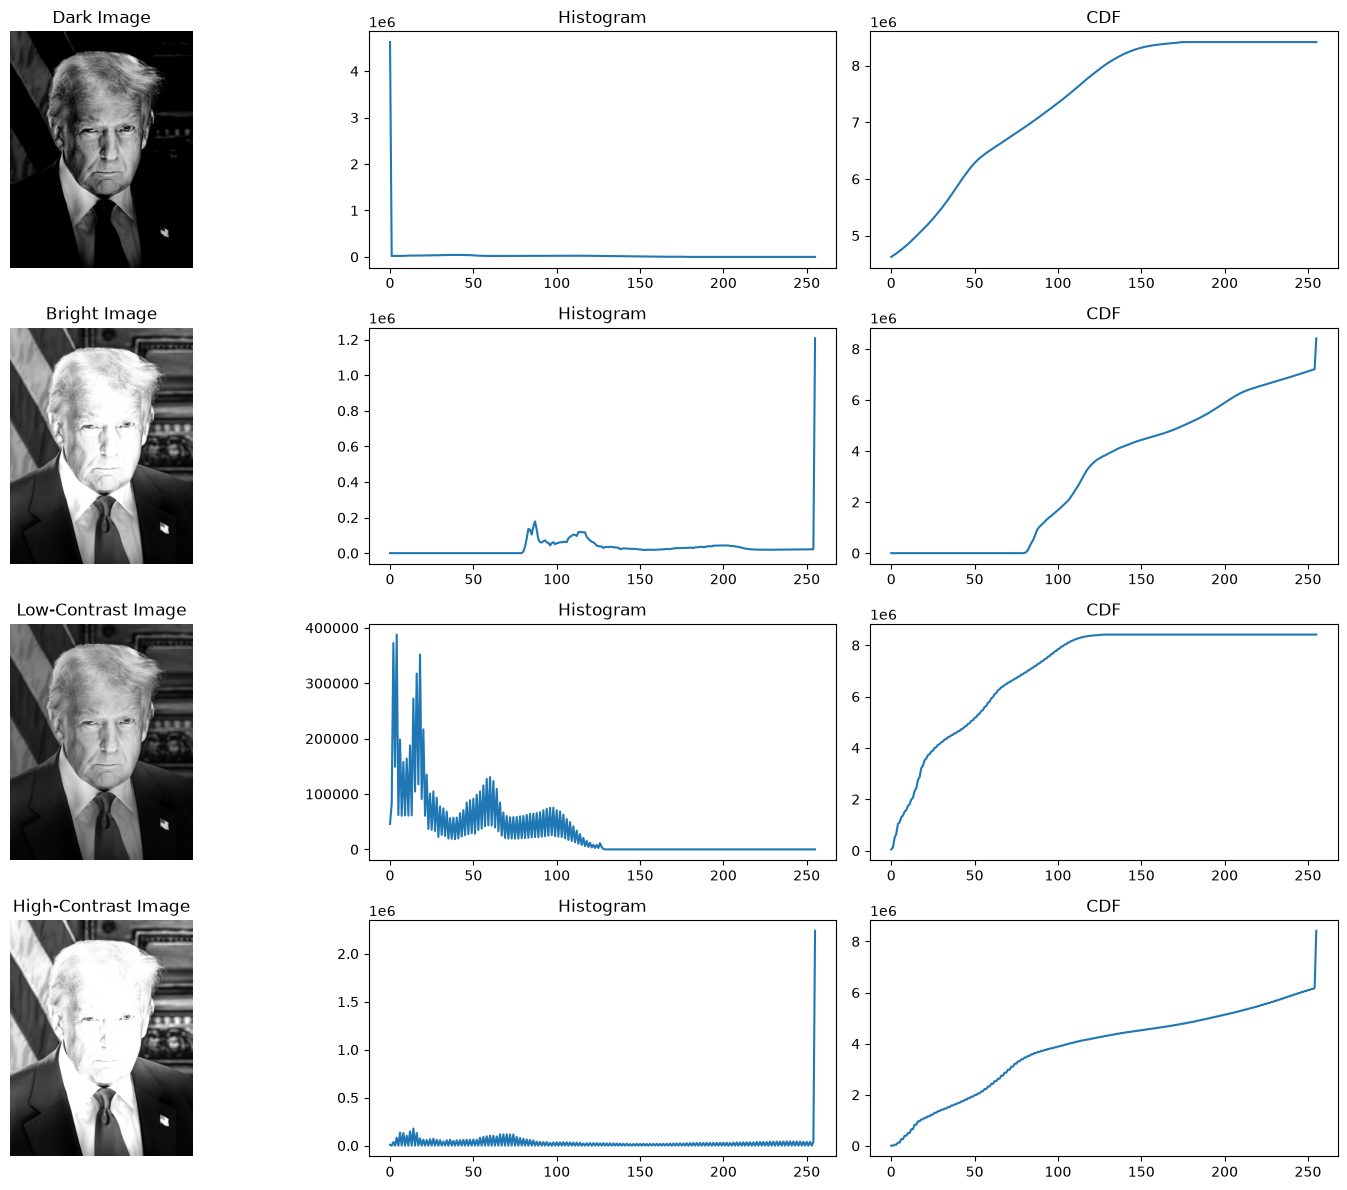

In [14]:
plt.figure(figsize=(15, 12))

for i in range(len(images)):
    img = images[i]
    histogram = cv2.calcHist([img], [0], None, [256], [0, 256]).flatten()
    cdf = np.cumsum(histogram)

    plt.subplot(4, 3, i * 3 + 1)
    plt.imshow(img, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

    plt.subplot(4, 3, i * 3 + 2)
    plt.plot(histogram)
    plt.title("Histogram")

    plt.subplot(4, 3, i * 3 + 3)
    plt.plot(cdf)
    plt.title("CDF")

plt.tight_layout()

In [15]:
print("Dark image: Histogram values are concentrated toward lower intensities.")
print("Bright image: Histogram values are concentrated toward higher intensities.")
print("Low-contrast image: Histogram values occupy a narrow intensity range.")
print("High-contrast image: Histogram values generally cover a wider intensity range.")
print("The CDF shows the cumulative number of pixels up to each intensity value.")

Dark image: Histogram values are concentrated toward lower intensities.
Bright image: Histogram values are concentrated toward higher intensities.
Low-contrast image: Histogram values occupy a narrow intensity range.
High-contrast image: Histogram values generally cover a wider intensity range.
The CDF shows the cumulative number of pixels up to each intensity value.
